In [1]:
# CATTLE HEALTH PREDICTION 
# Goal:   use a cow's body measurements to predict if it is
#         healthy or unhealthy, and find which measurements
#         matter most.
# Data:   Kaggle "Cow Health Prediction" (178 rows, 14 columns)
# Method: clean the data, explore it, train a decision tree and
#         a random forest, and test them honestly.
# 1. SETUP
# All tools are loaded in this one cell, so the notebook runs
# from top to bottom without errors.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import set_config
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

set_config(display="text")

In [2]:
# 2. LOAD THE DATA
# Read the Excel file into a table called df.

df = pd.read_excel("data/cattle_dataset.xlsx")

In [3]:
# 3. LOOK AT THE DATA
# Check the size, the column types, the missing values and the
# text columns.
#  - There are no missing values.
#  - There are 3 text columns.
#  - faecal_consistency has a spelling problem.

df.shape

(178, 14)

In [4]:
df.head()

,body_temperature,breed_type,milk_production,respiratory_rate,walking_capacity,sleeping_duration,body_condition_score,heart_rate,eating_duration,lying_down_duration,ruminating,rumen_fill,faecal_consistency,health_status
0,38.2,Cross Breed,13.6,36,12432,3.5,3,50,3.2,15.0,6.0,3,extremely firm,unhealthy
1,38.9,Normal Breed,24.1,37,11987,4.2,2,62,3.9,12.2,5.8,4,ideal,healthy
2,38.6,Cross Breed,14.7,42,13121,3.2,3,71,3.0,12.6,5.9,2,ideal,healthy
3,39.5,Normal Breed,26.2,29,12055,3.8,4,68,3.6,13.5,6.0,2,Black faece,unhealthy
4,39.7,Normal Breed,22.5,48,10352,4.6,2,63,3.1,13.5,6.3,5,ideal,healthy


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   body_temperature      178 non-null    float64
 1   breed_type            178 non-null    str    
 2   milk_production       178 non-null    float64
 3   respiratory_rate      178 non-null    int64  
 4   walking_capacity      178 non-null    int64  
 5   sleeping_duration     178 non-null    float64
 6   body_condition_score  178 non-null    int64  
 7   heart_rate            178 non-null    int64  
 8   eating_duration       178 non-null    float64
 9   lying_down_duration   178 non-null    float64
 10  ruminating            178 non-null    float64
 11  rumen_fill            178 non-null    int64  
 12  faecal_consistency    178 non-null    str    
 13  health_status         178 non-null    str    
dtypes: float64(6), int64(5), str(3)
memory usage: 19.6 KB


In [6]:
df.describe().round(2)

,body_temperature,milk_production,respiratory_rate,walking_capacity,sleeping_duration,body_condition_score,heart_rate,eating_duration,lying_down_duration,ruminating,rumen_fill
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,39.01,14.77,28.69,9303.18,4.93,2.91,53.96,2.83,13.96,4.89,2.74
std,0.87,6.62,9.77,3237.39,1.56,1.25,13.16,0.76,1.51,1.17,1.05
min,35.50,5.10,14.00,5004.00,2.80,1.00,37.00,1.30,6.00,3.00,1.00
25%,38.30,9.70,21.00,6019.00,3.50,2.00,42.00,2.20,12.90,3.60,2.00
50%,38.90,13.60,28.00,11203.00,4.20,3.00,50.00,2.90,13.80,5.00,3.00
75%,39.70,21.20,36.00,12291.00,6.50,4.00,63.00,3.40,15.10,5.90,3.00
max,40.60,26.50,49.00,13257.00,7.20,5.00,83.00,4.90,16.40,7.00,5.00


In [7]:
df["health_status"].value_counts()

health_status
healthy      90
unhealthy    88
Name: count, dtype: int64

In [8]:
df["breed_type"].value_counts()

breed_type
Cross Breed     90
Normal Breed    88
Name: count, dtype: int64

In [9]:
df["faecal_consistency"].value_counts()

faecal_consistency
ideal                    90
extremely firm           24
Black faeces             22
Fresh blood in faeces    20
very liquid faeces       20
Black faece               2
Name: count, dtype: int64

In [10]:
# 4. CLEAN THE DATA
# Typo: "Black faece" and "Black faeces" mean the same thing.
#       I fix it on a copy of the table.
# Duplicates: 89 rows are exact copies, so there are only 89
#       real cows. A copy in both the training group and the
#       test group would give a fake score.
# One cold cow (35.5 degrees C): I cannot tell if it is real or
#       a typing mistake, so I keep it.

df_clean = df.copy()

In [11]:
df_clean["faecal_consistency"] = df_clean["faecal_consistency"].replace("Black faece", "Black faeces")

In [12]:
df_clean["faecal_consistency"].value_counts()

faecal_consistency
ideal                    90
extremely firm           24
Black faeces             24
Fresh blood in faeces    20
very liquid faeces       20
Name: count, dtype: int64

In [13]:
df_clean.duplicated().sum()

np.int64(89)

In [14]:
df_unique = df_clean.drop_duplicates()

In [15]:
df_unique.shape

(89, 14)

In [16]:
df_unique["health_status"].value_counts()

health_status
healthy      45
unhealthy    44
Name: count, dtype: int64

In [17]:
df_unique.duplicated().sum()

np.int64(0)

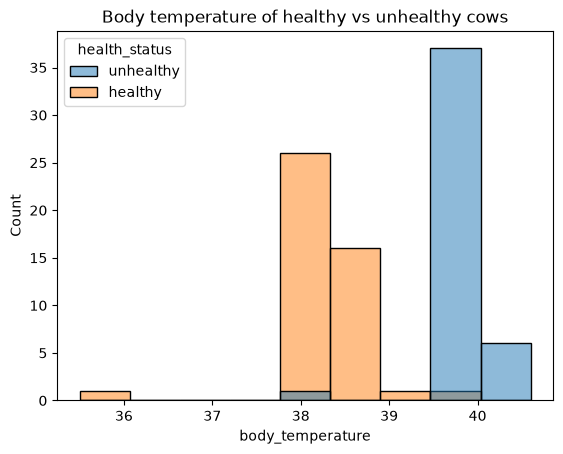

In [18]:
# 5. EXPLORE THE DATA
# Charts and correlations show how healthy and unhealthy cows
# differ.
#  - Unhealthy cows have a higher body temperature, sleep more
#    and walk less.
#  - Strongest links with health status: walking_capacity
#    (-0.93), sleeping_duration (+0.91), body_temperature (+0.86).
#  - body_condition_score shows no difference (correlation 0.02).

sns.histplot(data=df_unique, x="body_temperature", hue="health_status")
plt.title("Body temperature of healthy vs unhealthy cows")
plt.show()

In [19]:
df_unique.info()

<class 'pandas.DataFrame'>
RangeIndex: 89 entries, 0 to 88
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   body_temperature      89 non-null     float64
 1   breed_type            89 non-null     str    
 2   milk_production       89 non-null     float64
 3   respiratory_rate      89 non-null     int64  
 4   walking_capacity      89 non-null     int64  
 5   sleeping_duration     89 non-null     float64
 6   body_condition_score  89 non-null     int64  
 7   heart_rate            89 non-null     int64  
 8   eating_duration       89 non-null     float64
 9   lying_down_duration   89 non-null     float64
 10  ruminating            89 non-null     float64
 11  rumen_fill            89 non-null     int64  
 12  faecal_consistency    89 non-null     str    
 13  health_status         89 non-null     str    
dtypes: float64(6), int64(5), str(3)
memory usage: 9.9 KB


In [20]:
num_cols = df_unique.select_dtypes(include="number").columns

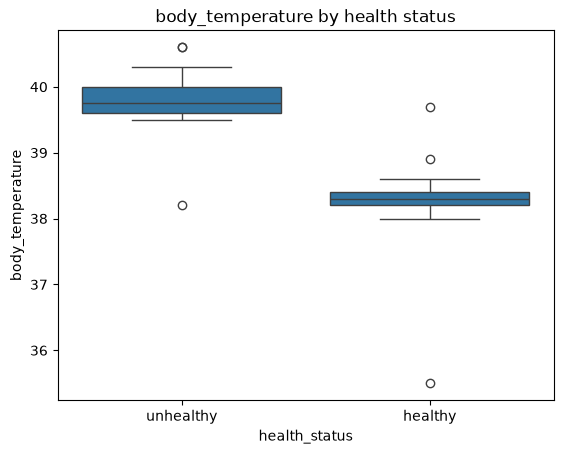

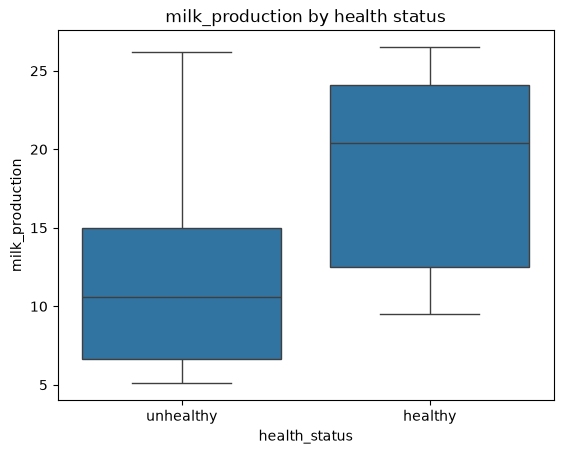

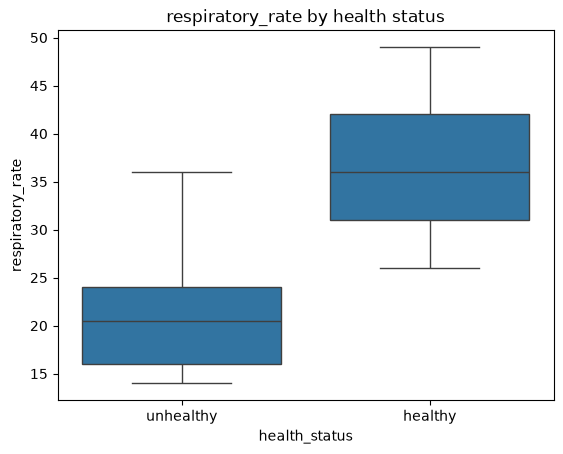

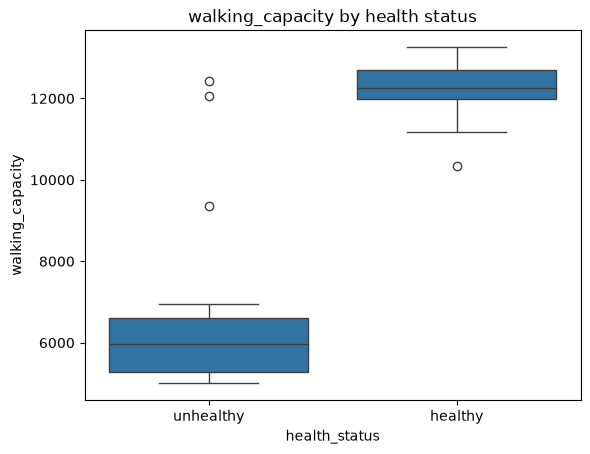

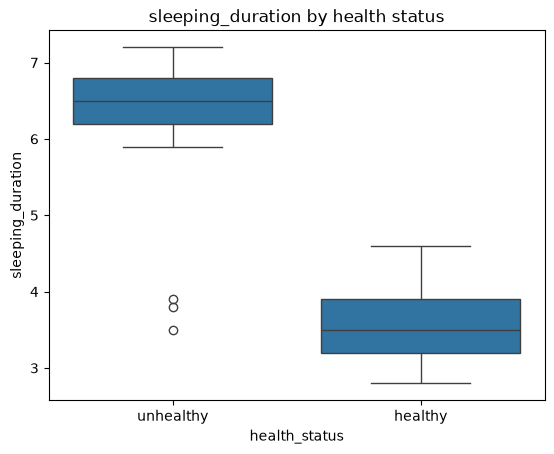

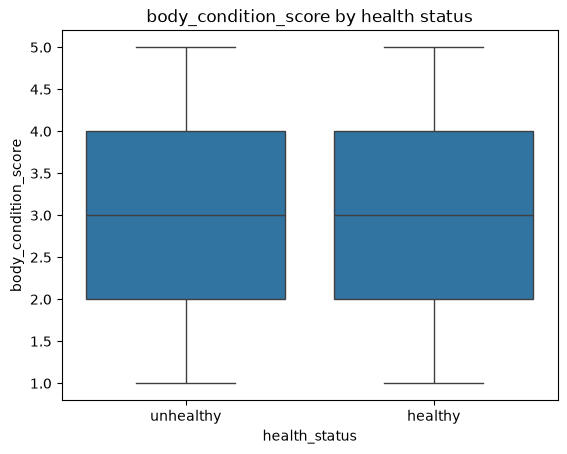

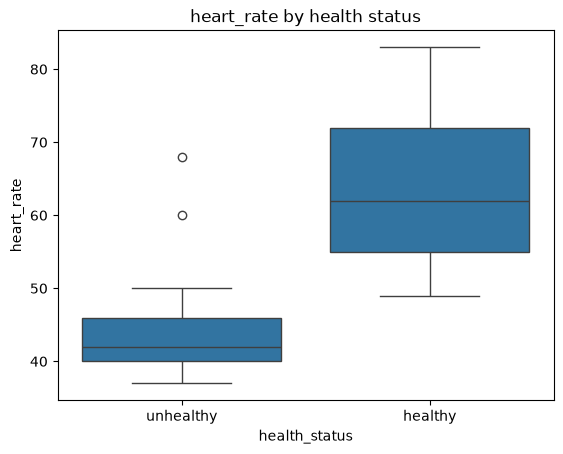

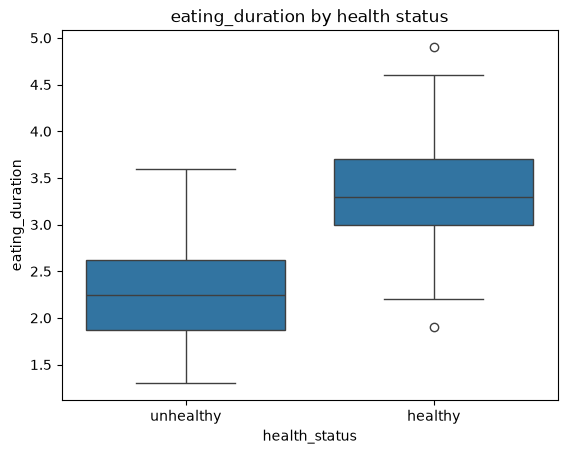

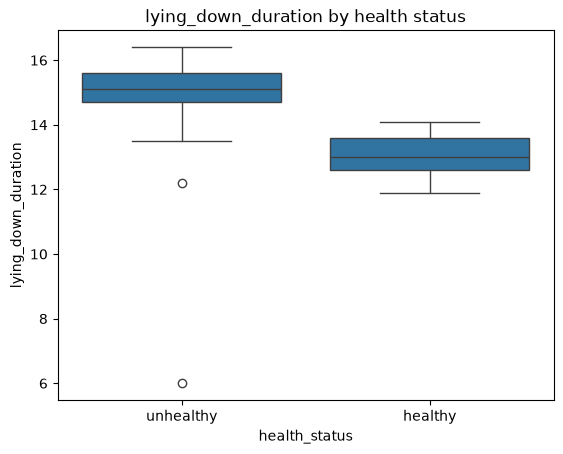

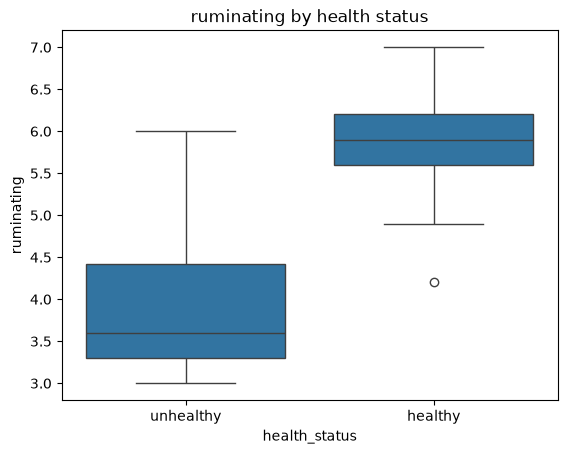

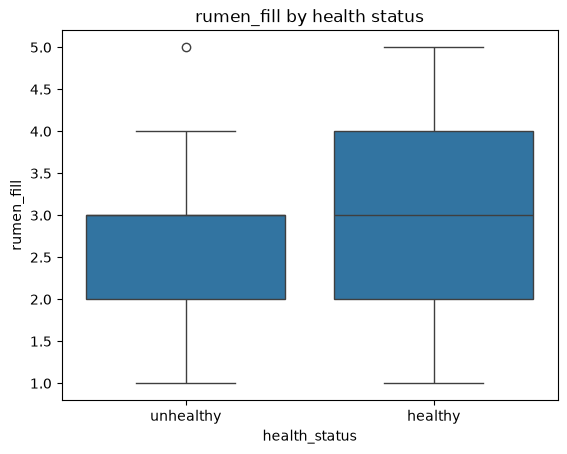

In [21]:
for col in num_cols:
    sns.boxplot(data=df_unique, x="health_status", y=col)
    plt.title(col + " by health status")
    plt.show()

In [22]:
target = df_unique["health_status"].map({"healthy": 0, "unhealthy": 1})

In [23]:
corr = df_unique[num_cols].corrwith(target)

In [24]:
corr.round(2).sort_values()

walking_capacity       -0.93
ruminating             -0.82
respiratory_rate       -0.79
heart_rate             -0.78
eating_duration        -0.69
milk_production        -0.57
rumen_fill             -0.19
body_condition_score    0.02
lying_down_duration     0.62
body_temperature        0.86
sleeping_duration       0.91
dtype: float64

In [25]:
corr.abs().sort_values(ascending=False)

walking_capacity        0.934301
sleeping_duration       0.914195
body_temperature        0.863141
ruminating              0.818244
respiratory_rate        0.789375
heart_rate              0.784502
eating_duration         0.688571
lying_down_duration     0.617984
milk_production         0.565875
rumen_fill              0.185704
body_condition_score    0.017157
dtype: float64

In [26]:
# 6. PREPARE THE DATA
# X = the 13 clues. y = the answer (healthy = 0, unhealthy = 1).
# One-hot encoding turns the text columns into 0/1 columns, so
# the table has 18 columns.
# Split: 66 cows for training and 23 for testing, with the
# healthy/unhealthy balance kept the same.
y = target
X = df_unique.drop(columns=["health_status"])

In [27]:
print(X.shape)
print(y.shape)

(89, 13)
(89,)


In [28]:
X_encoded = pd.get_dummies(X, columns=["breed_type", "faecal_consistency"], dtype=int)

In [29]:
X_encoded.shape

(89, 18)

In [30]:
X_encoded.info()

<class 'pandas.DataFrame'>
RangeIndex: 89 entries, 0 to 88
Data columns (total 18 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   body_temperature                          89 non-null     float64
 1   milk_production                           89 non-null     float64
 2   respiratory_rate                          89 non-null     int64  
 3   walking_capacity                          89 non-null     int64  
 4   sleeping_duration                         89 non-null     float64
 5   body_condition_score                      89 non-null     int64  
 6   heart_rate                                89 non-null     int64  
 7   eating_duration                           89 non-null     float64
 8   lying_down_duration                       89 non-null     float64
 9   ruminating                                89 non-null     float64
 10  rumen_fill                                89 non-nu

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.25, random_state=42, stratify=y
)

In [32]:
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(66, 18) (23, 18)
(66,) (23,)


In [33]:
print(y_train.value_counts())
print(y_test.value_counts())

health_status
0    33
1    33
Name: count, dtype: int64
health_status
0    12
1    11
Name: count, dtype: int64


In [34]:
# 7. FIRST MODEL: A SHORTCUT
# A decision tree scored 100%, but it used only ONE column:
# faecal_consistency_ideal.
# Every healthy cow has "ideal" and no sick cow has it, so the
# model found a shortcut and learned nothing about the other
# measurements.

model = DecisionTreeClassifier(random_state=42)

In [35]:
model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [36]:
print("Training score:", model.score(X_train, y_train))
print("Test score:", model.score(X_test, y_test))

Training score: 1.0
Test score: 1.0


In [37]:
print("Depth:", model.get_depth())
print("Leaves:", model.get_n_leaves())

Depth: 1
Leaves: 2


In [38]:
from sklearn.tree import export_text
print(export_text(model, feature_names=list(X_train.columns)))

|--- faecal_consistency_ideal <= 0.50
|   |--- class: 1
|--- faecal_consistency_ideal >  0.50
|   |--- class: 0



In [39]:
# 8. HONEST DECISION TREE
# I remove all the faecal_consistency columns and train again.
#  - Training score: 1.0
#  - Test score: 0.9565 (22 of 23 cows right)
#  - The tree asks about walking_capacity first, then
#    lying_down_duration.

faecal_cols = X_train.filter(like="faecal").columns
print(faecal_cols)

Index(['faecal_consistency_Black faeces',
       'faecal_consistency_Fresh blood in faeces',
       'faecal_consistency_extremely firm', 'faecal_consistency_ideal',
       'faecal_consistency_very liquid faeces'],
      dtype='str')


In [40]:
X_train_honest = X_train.drop(columns=faecal_cols)
X_test_honest = X_test.drop(columns=faecal_cols)

In [41]:
print(X_train_honest.shape, X_test_honest.shape)
print(list(X_train_honest.columns))

(66, 13) (23, 13)
['body_temperature', 'milk_production', 'respiratory_rate', 'walking_capacity', 'sleeping_duration', 'body_condition_score', 'heart_rate', 'eating_duration', 'lying_down_duration', 'ruminating', 'rumen_fill', 'breed_type_Cross Breed', 'breed_type_Normal Breed']


In [42]:
model_honest = DecisionTreeClassifier(random_state=42)
model_honest.fit(X_train_honest, y_train)

DecisionTreeClassifier(random_state=42)

In [43]:
print("Training score:", model_honest.score(X_train_honest, y_train))
print("Test score:", model_honest.score(X_test_honest, y_test))

Training score: 1.0
Test score: 0.9565217391304348


In [44]:
print("Depth:", model_honest.get_depth())
print("Leaves:", model_honest.get_n_leaves())
print(export_text(model_honest, feature_names=list(X_train_honest.columns)))

Depth: 2
Leaves: 3
|--- walking_capacity <= 9852.00
|   |--- class: 1
|--- walking_capacity >  9852.00
|   |--- lying_down_duration <= 14.55
|   |   |--- class: 0
|   |--- lying_down_duration >  14.55
|   |   |--- class: 1



In [45]:
predictions_honest = model_honest.predict(X_test_honest)

In [46]:
results = pd.DataFrame({"actual": y_test, "predicted": predictions_honest})
results.head()

,actual,predicted
3,1,0
59,0,0
23,0,0
72,1,1
27,1,1


In [47]:
results[results["actual"] != results["predicted"]]

,actual,predicted
3,1,0


In [48]:
df_unique.loc[3]

body_temperature                39.5
breed_type              Normal Breed
milk_production                 26.2
respiratory_rate                  29
walking_capacity               12055
sleeping_duration                3.8
body_condition_score               4
heart_rate                        68
eating_duration                  3.6
lying_down_duration             13.5
ruminating                       6.0
rumen_fill                         2
faecal_consistency      Black faeces
health_status              unhealthy
Name: 3, dtype: object

In [49]:
# 9. EVALUATE THE HONEST TREE
# Confusion matrix (rows = truth, columns = model's answer):
#  - 12 healthy cows right, 0 false alarms.
#  - 1 sick cow missed, 10 sick cows right.
# Healthy:   precision 0.92, recall 1.00
# Unhealthy: precision 1.00, recall 0.91
# The missed cow is cow 3. It is sick but looks healthy on
# walking, sleeping and heart rate. Missing a sick cow is the
# most costly mistake on a farm.

print(confusion_matrix(y_test, predictions_honest))

[[12  0]
 [ 1 10]]


In [50]:
from sklearn.metrics import classification_report
print(classification_report(y_test, predictions_honest, target_names=["healthy", "unhealthy"]))

              precision    recall  f1-score   support

     healthy       0.92      1.00      0.96        12
   unhealthy       1.00      0.91      0.95        11

    accuracy                           0.96        23
   macro avg       0.96      0.95      0.96        23
weighted avg       0.96      0.96      0.96        23



In [51]:
# 10. RANDOM FOREST AND FEATURE IMPORTANCE
# A random forest is 100 trees that vote.
#  - Same score as the tree (0.9565) and the same missed cow.
#  - Five main clues: heart rate, walking capacity, lying-down
#    time, body temperature, sleeping time.
#  - With a different random seed the same five stay on top,
#    but their order changes.
#  - body_condition_score and breed carry almost nothing.

forest = RandomForestClassifier(n_estimators=100, random_state=42)

In [52]:
forest.fit(X_train_honest, y_train)

RandomForestClassifier(random_state=42)

In [53]:
print("Training score:", forest.score(X_train_honest, y_train))
print("Test score:", forest.score(X_test_honest, y_test))

Training score: 1.0


Test score: 0.9565217391304348


In [54]:
forest_predictions = forest.predict(X_test_honest)
print(confusion_matrix(y_test, forest_predictions))

[[12  0]
 [ 1 10]]


In [55]:
importances = pd.Series(forest.feature_importances_, index=X_train_honest.columns)
importances = importances.sort_values(ascending=False)
print(importances.round(3))

heart_rate                 0.207
walking_capacity           0.199
lying_down_duration        0.150
body_temperature           0.139
sleeping_duration          0.130
ruminating                 0.090
respiratory_rate           0.037
eating_duration            0.023
milk_production            0.017
rumen_fill                 0.007
breed_type_Cross Breed     0.001
breed_type_Normal Breed    0.000
body_condition_score       0.000
dtype: float64


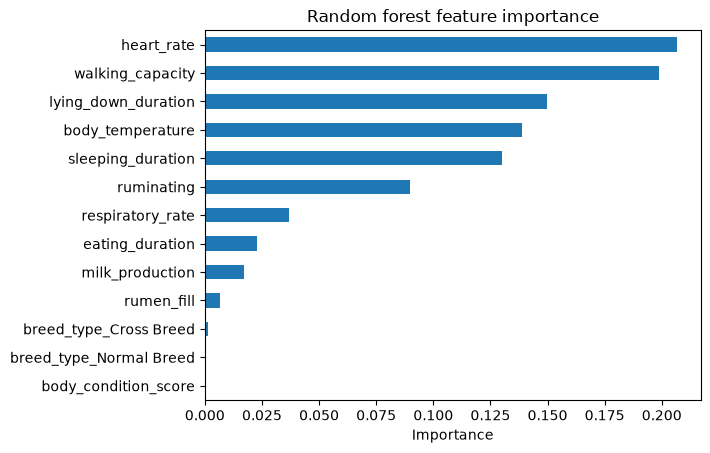

In [56]:
importances.sort_values().plot(kind="barh")
plt.title("Random forest feature importance")
plt.xlabel("Importance")
plt.show()

In [57]:
results_forest = pd.DataFrame({"actual": y_test, "predicted": forest_predictions})
results_forest[results_forest["actual"] != results_forest["predicted"]]

,actual,predicted
3,1,0


In [58]:
X_honest = X_encoded.drop(columns=faecal_cols)

for seed in [0, 1, 2]:
    f = RandomForestClassifier(n_estimators=100, random_state=seed)
    f.fit(X_honest, y)
    imp = pd.Series(f.feature_importances_, index=X_honest.columns).sort_values(ascending=False)
    print("Seed", seed, "top 5:", list(imp.index[:5]))

Seed 0 top 5: ['walking_capacity', 'lying_down_duration', 'body_temperature', 'sleeping_duration', 'heart_rate']
Seed 1 top 5: ['heart_rate', 'body_temperature', 'walking_capacity', 'sleeping_duration', 'lying_down_duration']
Seed 2 top 5: ['walking_capacity', 'body_temperature', 'heart_rate', 'sleeping_duration', 'lying_down_duration']


In [59]:
# 11. CROSS-VALIDATION
# One test group of 23 cows is a shaky judge. In 5-fold
# cross-validation every cow is tested exactly once.
#  - Tree, without shortcut:    0.955
#  - Forest, without shortcut:  0.966
#  - Tree, with shortcut:       1.000
#  - Forest, with shortcut:     0.966
# The tree and the forest are tied (about one cow apart). The
# tree with the shortcut is perfect in every fold, which
# confirms the shortcut.

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [60]:
tree_honest = cross_val_score(DecisionTreeClassifier(random_state=42), X_honest, y, cv=cv)
print("Tree, honest:", tree_honest.round(3))
print("Mean:", round(tree_honest.mean(), 3), "  Std:", round(tree_honest.std(), 3))

Tree, honest: [0.944 1.    0.889 1.    0.941]
Mean: 0.955   Std: 0.042


In [61]:
forest_honest = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), X_honest, y, cv=cv)
print("Forest, honest:", forest_honest.round(3))
print("Mean:", round(forest_honest.mean(), 3), "  Std:", round(forest_honest.std(), 3))

Forest, honest: [1.    1.    0.889 1.    0.941]
Mean: 0.966   Std: 0.045


In [62]:
tree_all = cross_val_score(DecisionTreeClassifier(random_state=42), X_encoded, y, cv=cv)
print("Tree, with shortcut:", tree_all.round(3))
print("Mean:", round(tree_all.mean(), 3), "  Std:", round(tree_all.std(), 3))

Tree, with shortcut: [1. 1. 1. 1. 1.]
Mean: 1.0   Std: 0.0


In [63]:
forest_all = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), X_encoded, y, cv=cv)
print("Forest, with shortcut:", forest_all.round(3))
print("Mean:", round(forest_all.mean(), 3), "  Std:", round(forest_all.std(), 3))

Forest, with shortcut: [1.    1.    0.889 1.    0.941]
Mean: 0.966   Std: 0.045


In [64]:
# 12. CONCLUSIONS AND LIMITS
# Results: after removing the duplicates and the shortcut
# column, both models reach about 95 to 97% accuracy.
# Main clues: walking capacity, body temperature, heart rate,
# sleeping time and lying-down time (their order changes with
# the random seed).
# Limits:
#  - Only 89 cows, from one dataset.
#  - The data looks unusually clean, so it may be partly simulated.
#  - Never tested on a different farm.
#  - Feature importance shows what the model used, not what
#    causes sickness.
# This is a proof of concept, not a tool for real farms.